# 03 · QSVM learning curves (main section, noiseless exact kernels)

Fidelity kernel SVM on three qubits, $K(x, x') = |\langle 000|S^\dagger(x) S(x')|000\rangle|^2$, with two feature maps:

* **angle**: one $R_y$ per qubit, closed form $\prod_j \cos^2((x_j - x'_j)/2)$ (synopsis eq. 5),
* **ZZ**: Havlicek et al. map, `zz_feature_map(3, reps = 2, entanglement = "linear")`.

Inputs are the angle-scaled features times a bandwidth $c$. Noiseless kernels are computed exactly from state vectors
(three qubits, checked against Qiskit in 00). The QSVM tunes $(c, C)$ over 5 x 5 = 25 settings on the same inner folds as
the RBF SVM's 25 settings, so both get the same tuning effort.

A **matched-width RBF** control is also run: for small differences the angle kernel is $\approx \exp(-c^2\|x - x'\|^2/4)$,
so an RBF SVM with $\gamma = c^2/4$ (using the $c$ the angle QSVM picked on the same training set) shows whether the
angle QSVM is anything more than a fixed-width RBF.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /kaggle/working/Project


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from qsvm_rc import config, data_utils, metrics, models, plots, quantum_kernels

SECTION = config.MAIN_SECTION
RESULTS_DIR = config.section_results_dir(SECTION, "qsvm")

ANGLE_SPEC = {"kind": "angle"}
ZZ_SPEC = {"kind": "zz", "reps": 2, "entanglement": "linear"}

In [3]:
frame = data_utils.load_section(SECTION)
splits = data_utils.load_splits(SECTION)
scaler = data_utils.domain_scaler(SECTION, frame)
test_rows, band_mask = data_utils.test_indices(splits)
x_test, y_test = data_utils.features_and_labels(frame, test_rows, scaler)
test_cache = models.ExactStateCache(x_test)
print(f"Test set: {len(test_rows)} rows ({int(band_mask.sum())} in the band)")

Test set: 4000 rows (1000 in the band)


## 1. Look at the circuits

angle feature map S(x):


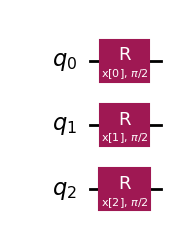

ZZ feature map S(x):


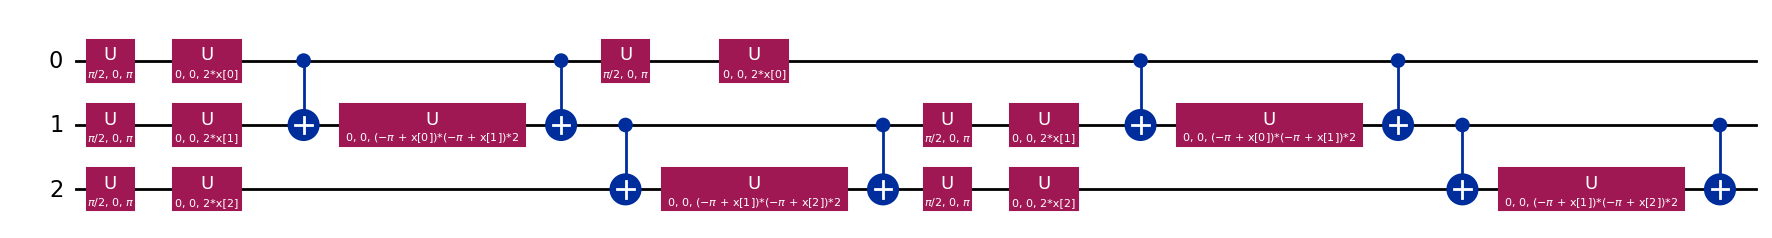

In [4]:
for name, spec in [("angle", ANGLE_SPEC), ("ZZ", ZZ_SPEC)]:
    feature_map = quantum_kernels.build_feature_map(spec)
    print(f"{name} feature map S(x):")
    display(feature_map.decompose().draw("mpl", fold = -1))

Compute-uncompute circuit for the ZZ kernel (what hardware runs for one pair):


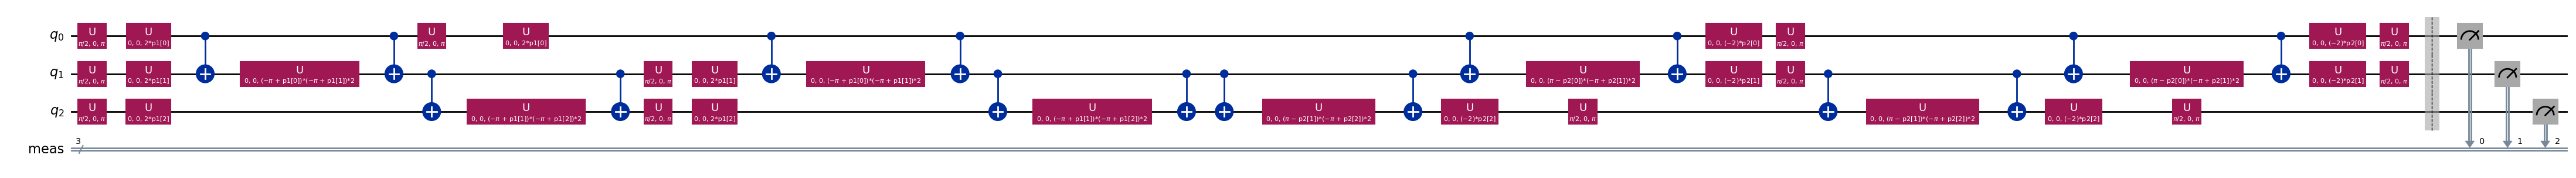

In [5]:
zz_overlap = quantum_kernels.overlap_template(quantum_kernels.build_feature_map(ZZ_SPEC))
print("Compute-uncompute circuit for the ZZ kernel (what hardware runs for one pair):")
display(zz_overlap.decompose().draw("mpl", fold = -1))

In [6]:
print(quantum_kernels.circuit_resources(quantum_kernels.transpile_for_simulation(zz_overlap)))

{'qubits_used': 3, 'depth': 39, 'two_qubit_gates': 14, 'total_gates': 70}


## 2. Look at the kernel before training anything

Training set n = 160, seed 0, sorted SAFE first. A useful kernel shows two bright blocks. Too small $c$ gives a sheet of
ones, too large $c$ gives the identity (concentration).

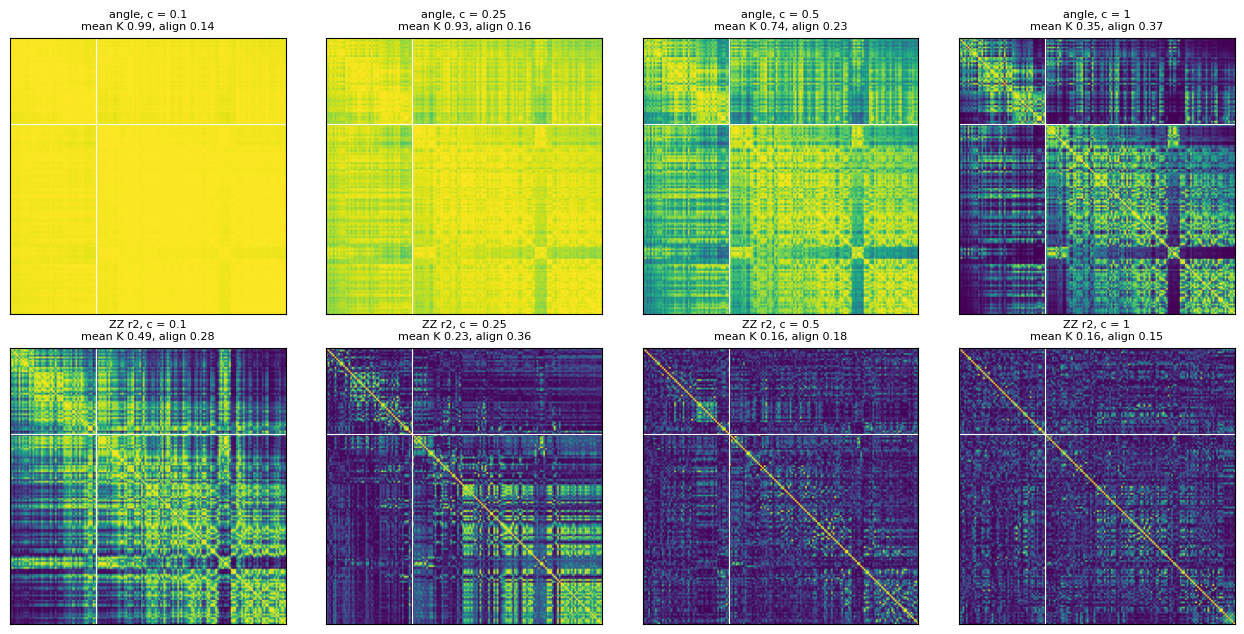

In [7]:
train_rows = data_utils.training_indices(splits, 160, 0, "random")
x_train, y_train = data_utils.features_and_labels(frame, train_rows, scaler)
order = np.argsort(-y_train)
number_safe = int(np.sum(y_train == 1))

bandwidths_to_show = [0.1, 0.25, 0.5, 1]
figure, axes = plt.subplots(2, len(bandwidths_to_show), figsize = (3.2 * len(bandwidths_to_show), 6.4))
for row, (name, spec) in enumerate([("angle", ANGLE_SPEC), ("ZZ r2", ZZ_SPEC)]):
    for column, bandwidth in enumerate(bandwidths_to_show):
        gram = quantum_kernels.exact_gram(spec, models.encode(x_train, spec, bandwidth))
        diagnostics = metrics.kernel_diagnostics(gram, y_train)
        axis = axes[row, column]
        axis.imshow(gram[np.ix_(order, order)], vmin = 0, vmax = 1, cmap = "viridis")
        axis.axhline(number_safe - 0.5, color = "w", linewidth = 0.8)
        axis.axvline(number_safe - 0.5, color = "w", linewidth = 0.8)
        mean_kernel = diagnostics["mean_offdiag"]
        alignment = diagnostics["target_alignment"]
        axis.set_title(f"{name}, c = {bandwidth}\nmean K {mean_kernel:.2f}, align {alignment:.2f}", fontsize = 8)
        axis.set_xticks([])
        axis.set_yticks([])
figure.tight_layout()
figure.savefig(config.figures_dir() / "qsvm_kernel_heatmaps.png", dpi = 200)
plt.show()

## 3. Learning curves

`rbf_svm` is re-run here on the same rows so the falsifier check below is self-contained (it is cheap).

In [8]:
def matched_width_rbf(x_train, y_train, x_test, seed):
    """RBF with gamma = c^2 / 4, where c is the bandwidth the angle QSVM picks on this training set."""
    bandwidth, _, _, _ = models.tune_qsvm(ANGLE_SPEC, x_train, y_train, seed)
    return models.matched_rbf_fit_predict(bandwidth)(x_train, y_train, x_test, seed)

quantum_models = {
    "qsvm_angle": models.qsvm_fit_predict(ANGLE_SPEC, test_cache),
    "qsvm_zz": models.qsvm_fit_predict(ZZ_SPEC, test_cache),
    "rbf_matched_width": matched_width_rbf,
    "rbf_svm": models.classical_fit_predict("rbf_svm"),
}

In [9]:
qsvm_results = models.run_learning_curve(quantum_models, frame, splits, scaler, strategy = "random",
                                         save_path = RESULTS_DIR / "learning_curves_random.csv")
print("Saved", len(qsvm_results), "rows")

qsvm_angle               n=20   seed=0  band_error=0.452  test_bal_acc=0.928  false_safe=0.000  (0.5 s)
qsvm_zz                  n=20   seed=0  band_error=0.446  test_bal_acc=0.757  false_safe=0.052  (0.6 s)
rbf_matched_width        n=20   seed=0  band_error=0.452  test_bal_acc=0.928  false_safe=0.000  (0.8 s)
rbf_svm                  n=20   seed=0  band_error=0.469  test_bal_acc=0.919  false_safe=0.000  (0.8 s)
qsvm_angle               n=20   seed=1  band_error=0.474  test_bal_acc=0.847  false_safe=0.123  (0.7 s)
qsvm_zz                  n=20   seed=1  band_error=0.444  test_bal_acc=0.793  false_safe=0.077  (0.6 s)
rbf_matched_width        n=20   seed=1  band_error=0.474  test_bal_acc=0.847  false_safe=0.123  (0.8 s)
rbf_svm                  n=20   seed=1  band_error=0.473  test_bal_acc=0.844  false_safe=0.124  (0.7 s)
qsvm_angle               n=20   seed=2  band_error=0.473  test_bal_acc=0.888  false_safe=0.006  (0.9 s)
qsvm_zz                  n=20   seed=2  band_error=0.468  test_b

In [10]:
key_metrics = ["band_error", "test_f1", "test_balanced_accuracy", "test_mcc", "test_false_safe_rate", "band_false_safe_rate"]
qsvm_table = metrics.mean_ci_table(qsvm_results, key_metrics)
qsvm_table.to_csv(RESULTS_DIR / "summary_random.csv")
qsvm_table

band_error          test_f1  \
model             train_size                                     
qsvm_angle        20          0.472 +/- 0.015  0.866 +/- 0.066   
                  40          0.436 +/- 0.037  0.927 +/- 0.027   
                  80          0.421 +/- 0.065  0.945 +/- 0.031   
                  160         0.395 +/- 0.033  0.968 +/- 0.012   
                  320         0.278 +/- 0.067  0.981 +/- 0.012   
qsvm_zz           20          0.465 +/- 0.032  0.706 +/- 0.200   
                  40          0.453 +/- 0.003  0.878 +/- 0.084   
                  80          0.410 +/- 0.037  0.938 +/- 0.013   
                  160         0.364 +/- 0.066  0.962 +/- 0.022   
                  320         0.316 +/- 0.065  0.974 +/- 0.011   
rbf_matched_width 20          0.472 +/- 0.015  0.865 +/- 0.066   
                  40          0.439 +/- 0.038  0.928 +/- 0.026   
                  80          0.425 +/- 0.056  0.944 +/- 0.031   
                  160         0.372 +/- 0.053  0.970 +/- 0.012   
                  320         0.324 +/- 0.083  0.977 +/- 0.010   
rbf_svm           20          0.482 +/- 0.023  0.854 +/- 0.066   
                  40          0.443 +/- 0.023  0.921 +/- 0.009   
                  80          0.430 +/- 0.055  0.939 +/- 0.026   
                  160         0.353 +/- 0.065  0.974 +/- 0.011   
                  320         0.359 +/- 0.075  0.971 +/- 0.012   

                             test_balanced_accuracy         test_mcc  \
model             train_size                                           
qsvm_angle        20                0.898 +/- 0.049  0.811 +/- 0.102   
                  40                0.943 +/- 0.021  0.895 +/- 0.040   
                  80                0.955 +/- 0.032  0.923 +/- 0.039   
                  160               0.978 +/- 0.010  0.954 +/- 0.018   
                  320               0.987 +/- 0.009  0.972 +/- 0.018   
qsvm_zz           20                0.796 +/- 0.134  0.628 +/- 0.192   
                  40                0.916 +/- 0.064  0.821 +/- 0.124   
                  80                0.953 +/- 0.012  0.911 +/- 0.020   
                  160               0.974 +/- 0.014  0.944 +/- 0.032   
                  320               0.982 +/- 0.008  0.962 +/- 0.016   
rbf_matched_width 20                0.898 +/- 0.049  0.810 +/- 0.102   
                  40                0.944 +/- 0.021  0.897 +/- 0.038   
                  80                0.955 +/- 0.031  0.922 +/- 0.038   
                  160               0.981 +/- 0.008  0.956 +/- 0.017   
                  320               0.984 +/- 0.008  0.967 +/- 0.015   
rbf_svm           20                0.888 +/- 0.036  0.791 +/- 0.105   
                  40                0.943 +/- 0.015  0.886 +/- 0.014   
                  80                0.952 +/- 0.023  0.912 +/- 0.036   
                  160               0.983 +/- 0.005  0.963 +/- 0.016   
                  320               0.979 +/- 0.008  0.957 +/- 0.018   

                             test_false_safe_rate band_false_safe_rate  
model             train_size                                            
qsvm_angle        20              0.052 +/- 0.066      0.385 +/- 0.413  
                  40              0.026 +/- 0.026      0.416 +/- 0.158  
                  80              0.014 +/- 0.015      0.386 +/- 0.315  
                  160             0.018 +/- 0.016      0.513 +/- 0.302  
                  320             0.011 +/- 0.008      0.305 +/- 0.061  
qsvm_zz           20              0.077 +/- 0.058      0.427 +/- 0.343  
                  40              0.070 +/- 0.038      0.518 +/- 0.072  
                  80              0.025 +/- 0.025      0.374 +/- 0.253  
                  160             0.023 +/- 0.015      0.449 +/- 0.165  
                  320             0.014 +/- 0.009      0.307 +/- 0.096  
rbf_matched_width 20              0.052 +/- 0.066      0.385 +/- 0.414  
                  40              0.025 +/- 0.02

In [11]:
# Tuned bandwidth and C, and the kernel diagnostics, per size
quantum_only = qsvm_results[qsvm_results["model"].isin(["qsvm_angle", "qsvm_zz"])]
quantum_only.groupby(["model", "train_size"])[["bandwidth", "C", "mean_offdiag", "min_eigenvalue", "target_alignment", "cv_balanced_accuracy"]].agg(["mean", "std"]).round(3)

bandwidth               C           mean_offdiag         \
                           mean    std     mean       std         mean    std   
model      train_size                                                           
qsvm_angle 20             0.020  0.017  10000.0     0.000        0.999  0.001   
           40             0.238  0.427   6200.2  5215.065        0.867  0.287   
           80             0.078  0.103   8020.0  4427.415        0.983  0.032   
           160            0.454  0.365   2224.0  4366.902        0.756  0.252   
           320            0.550  0.274    640.0   492.950        0.705  0.210   
qsvm_zz    20             0.078  0.103    260.2   415.777        0.754  0.350   
           40             0.038  0.038   2420.2  4263.894        0.849  0.238   
           80             0.020  0.017   6220.0  5185.750        0.964  0.051   
           160            0.054  0.045   6400.0  4929.503        0.763  0.257   
           320            0.032  0.016   8200.0  4024.922        0.926  0.060   

                      min_eigenvalue        target_alignment         \
                                mean    std             mean    std   
model      train_size                                                 
qsvm_angle 20                  0.000  0.000            0.160  0.000   
           40                 -0.000  0.000            0.180  0.127   
           80                 -0.000  0.000            0.145  0.007   
           160                -0.000  0.000            0.212  0.070   
           320                -0.000  0.000            0.220  0.061   
qsvm_zz    20                  0.008  0.019            0.215  0.091   
           40                  0.000  0.000            0.166  0.058   
           80                 -0.000  0.000            0.149  0.011   
           160                -0.000  0.000            0.201  0.062   
           320                -0.000  0.000            0.157  0.015   

                      cv_balanced_accuracy         
                                      mean    std  
model      train_size                              
qsvm_angle 20                        0.953  0.065  
           40                        0.962  0.014  
           80                        0.984  0.018  
           160                       0.987  0.011  
           320                       0.996  0.004  
qsvm_zz    20                        0.933  0.059  
           40                        0.960  0.020  
           80                        0.975  0.011  
           160                       0.989  0.009  
           320                       0.993  0.004

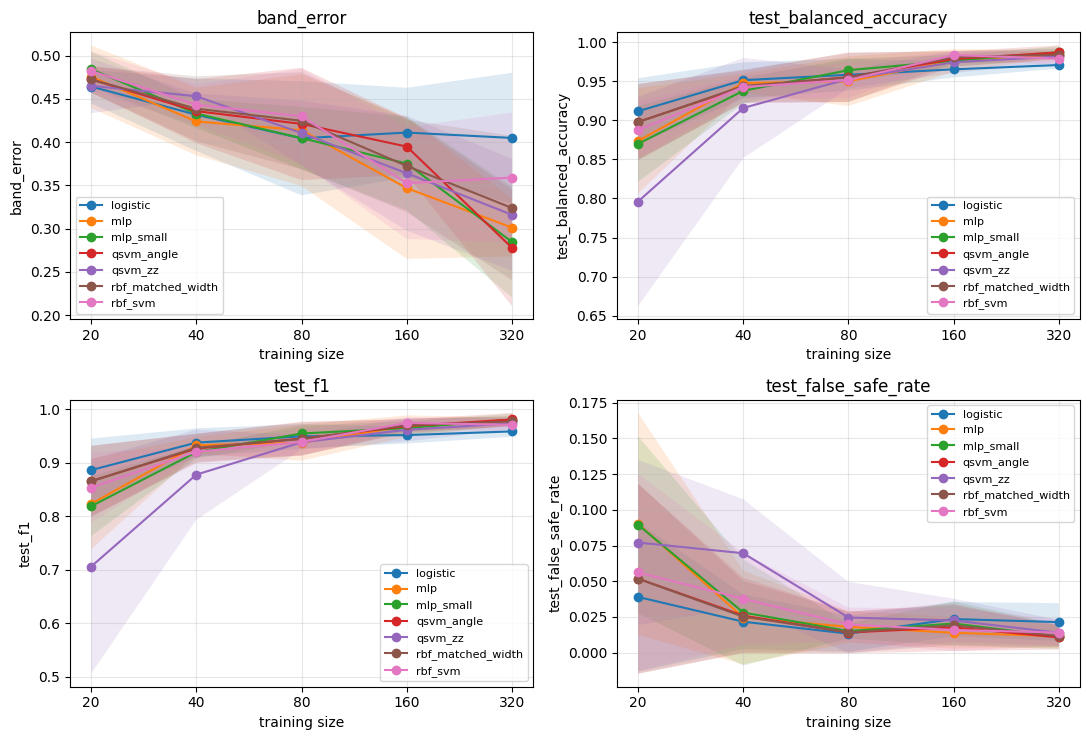

In [12]:
classical_path = config.section_results_dir(SECTION, "classical") / "learning_curves_random.csv"
combined = qsvm_results.copy()
if classical_path.exists():
    classical_results = pd.read_csv(classical_path)
    combined = pd.concat([classical_results[classical_results["model"] != "rbf_svm"], qsvm_results], ignore_index = True)
else:
    print("Classical results not found, plotting the QSVM run only.")

figure, axes = plt.subplots(2, 2, figsize = (11, 7.5))
for axis, metric_name in zip(axes.ravel(), ["band_error", "test_balanced_accuracy", "test_f1", "test_false_safe_rate"]):
    plots.learning_curve_plot(combined[combined["model"] != "majority"], metric_name, axis = axis, title = metric_name)
figure.tight_layout()
figure.savefig(config.figures_dir() / "qsvm_vs_classical_learning_curves.png", dpi = 200)
plt.show()

## 4. Falsifier check (preliminary, the final version is in 06)

Paired over seeds on identical training sets. Negative difference = the QSVM has the lower boundary error.
The hypothesis survives only if the 95 percent CI of the difference lies entirely below zero.

In [13]:
for quantum_model in ["qsvm_angle", "qsvm_zz"]:
    comparison = metrics.paired_comparison(qsvm_results, quantum_model, "rbf_svm", "band_error")
    print(f"\n{quantum_model} minus rbf_svm, band error")
    print(comparison.round(4).to_string(index = False))
    pooled = comparison[comparison["train_size"] == "pooled"].iloc[0]
    verdict = "SUPPORTED (CI below zero)" if pooled["ci95_high"] < 0 else "REJECTED (CI not below zero)"
    print("Pooled verdict:", verdict)


qsvm_angle minus rbf_svm, band error
train_size  pairs  mean_band_error_qsvm_angle  mean_band_error_rbf_svm  mean_difference  ci95_low  ci95_high  wins_for_a  ties  t_test_p  wilcoxon_p
        20      5                      0.4724                   0.4822          -0.0098   -0.0258     0.0062           3     1    0.1649      0.2500
        40      5                      0.4358                   0.4432          -0.0074   -0.0261     0.0113           3     1    0.3340      0.3750
        80      5                      0.4210                   0.4298          -0.0088   -0.0783     0.0607           3     0    0.7430      0.8125
       160      5                      0.3948                   0.3526           0.0422   -0.0372     0.1216           2     0    0.2141      0.3125
       320      5                      0.2778                   0.3590          -0.0812   -0.2200     0.0576           4     0    0.1797      0.3125
    pooled     25                      0.4004                   0.41

## 5. Leakage check

Train on permuted labels. Test balanced accuracy must collapse to about 0.5, otherwise information crosses the split.

In [14]:
shuffle_rng = np.random.default_rng(config.run_seed(config.SEED, 99))
leak_rows = []
for train_seed in config.TRAIN_SEEDS:
    rows = data_utils.training_indices(splits, 160, train_seed, "random")
    x_shuffle, y_shuffle = data_utils.features_and_labels(frame, rows, scaler)
    y_shuffle = shuffle_rng.permutation(y_shuffle)
    for name, spec in [("qsvm_angle", ANGLE_SPEC), ("qsvm_zz", ZZ_SPEC)]:
        predictions, _ = models.qsvm_fit_predict(spec, test_cache)(x_shuffle, y_shuffle, x_test, train_seed)
        leak_rows.append({"model": name, "seed": train_seed,
                          "test_balanced_accuracy": metrics.classification_metrics(y_test, predictions)["balanced_accuracy"]})
leak_table = pd.DataFrame(leak_rows).groupby("model")["test_balanced_accuracy"].agg(["mean", "std"])
print(leak_table.round(3))
print("PASS - no leakage detected" if (leak_table["mean"] < 0.5 + 2 * leak_table["std"] + 0.02).all() else "CHECK - investigate")

             mean    std
model                   
qsvm_angle  0.540  0.061
qsvm_zz     0.506  0.027
PASS - no leakage detected


## 6. Predicted SAFE regions at fixed loads (n = 320, seed 0)

qsvm_angle  c = 0.5, C = 100.0, inner CV 0.993
qsvm_zz     c = 0.02, C = 10000.0, inner CV 0.988
rbf_svm     {'C': 100, 'gamma': 0.001}


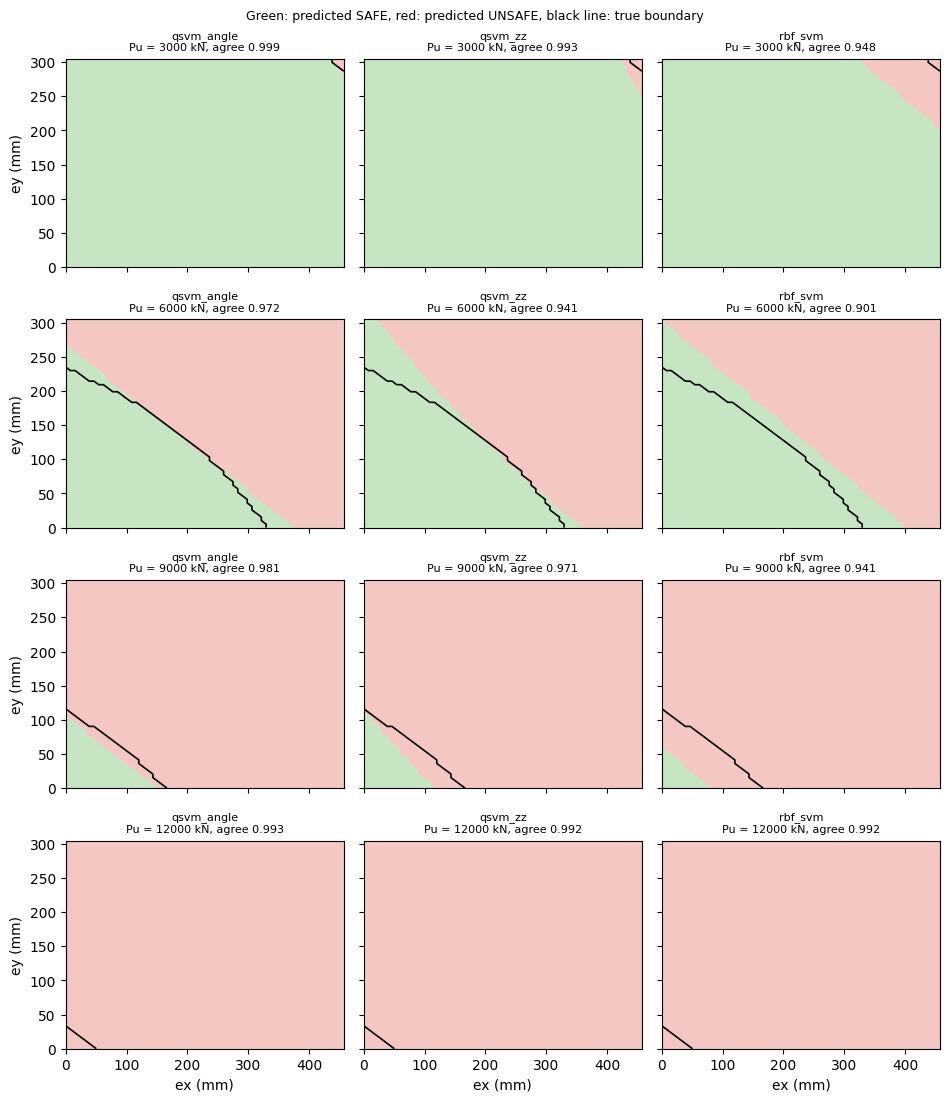

In [15]:
train_rows = data_utils.training_indices(splits, 320, 0, "random")
x_train, y_train = data_utils.features_and_labels(frame, train_rows, scaler)
seed_zero = config.run_seed(config.SEED, 0)

predictors = {}
chosen_settings = {}
for name, spec in [("qsvm_angle", ANGLE_SPEC), ("qsvm_zz", ZZ_SPEC)]:
    bandwidth, c_value, cv_score, _ = models.tune_qsvm(spec, x_train, y_train, seed_zero)
    chosen_settings[name] = (bandwidth, c_value)
    predictors[name] = models.exact_qsvm_predictor(spec, x_train, y_train, bandwidth, c_value)
    print(f"{name:<11} c = {bandwidth}, C = {c_value}, inner CV {cv_score:.3f}")
rbf_model, rbf_params, _ = models.fit_classical("rbf_svm", x_train, y_train, seed_zero)
predictors["rbf_svm"] = rbf_model.predict
print("rbf_svm    ", rbf_params)

figure = plots.safe_region_figure(SECTION, scaler, predictors, pu_levels = [3000, 6000, 9000, 12000])
figure.savefig(config.figures_dir() / "qsvm_safe_regions_n320.png", dpi = 200)
plt.show()

## 7. Save the settings the noise and hardware notebooks use

Most frequent tuned $(c, C)$ over the five seeds at n = 320 (ties go to the lower band error).

In [16]:
best_configs = {}
for name, spec in [("angle", ANGLE_SPEC), ("zz", ZZ_SPEC)]:
    setting = models.most_common_setting(qsvm_results, f"qsvm_{name}", 320)
    best_configs[name] = {"spec": spec, "bandwidth": setting["bandwidth"], "C": setting["C"]}
with open(RESULTS_DIR / "best_configs.json", "w") as handle:
    json.dump(best_configs, handle, indent = 2)
best_configs

{'angle': {'spec': {'kind': 'angle'}, 'bandwidth': 0.5, 'C': 100.0},
 'zz': {'spec': {'kind': 'zz', 'reps': 2, 'entanglement': 'linear'},
  'bandwidth': 0.02,
  'C': 10000.0}}

## 8. What the same study would cost with sampled kernels

One circuit per pair: $n(n-1)/2$ for the training kernel plus $n \times n_{test}$ for prediction.
This is why the noise study (05) runs on a subsample.

In [17]:
cost_rows = []
for size in config.TRAIN_SIZES:
    circuits = size * (size - 1) // 2 + size * len(test_rows)
    cost_rows.append({"train_size": size, "circuits_per_fit": circuits,
                      "shots_per_fit": circuits * config.SHOTS_KERNEL,
                      "circuits_whole_curve_one_model": circuits * len(config.TRAIN_SEEDS)})
cost_table = pd.DataFrame(cost_rows)
cost_table.to_csv(RESULTS_DIR / "sampled_kernel_cost.csv", index = False)
cost_table

,train_size,circuits_per_fit,shots_per_fit,circuits_whole_curve_one_model
0,20,80190,164229120,400950
1,40,160780,329277440,803900
2,80,323160,661831680,1615800
3,160,652720,1336770560,3263600
4,320,1331040,2725969920,6655200


Next: `03_quantum/02_vqc_sigmoid_optional.ipynb` (optional) or `04_ablations/01_encoding_ablations.ipynb`.